# 01 — Baseline GRU Replication
Exact replication of Dahm (2024) + extended evaluation metrics

In [13]:
# Install required packages
!pip install torch torchinfo tqdm

In [14]:
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.metrics import (
    mean_squared_error, mean_absolute_error,
    roc_auc_score, average_precision_score,
    f1_score, roc_curve
)

from tqdm.notebook import tqdm
from torchinfo import summary

print("All imports successful.")
print(f"PyTorch version: {torch.__version__}")

All imports successful.
PyTorch version: 2.14.1+cu130


## Cell 4 — Configuration
All hyperparameters are centralised in one `CONFIG` dict, matching Dahm (2024) exactly.

In [15]:
# ---------------------------------------------------------------------------
# Configuration — mirrors the original Forecasting_upload.py hyperparameters
# ---------------------------------------------------------------------------
# Auto-download repository if running in Colab or remote runtime
if not os.path.isdir('Nuclear-data-TS-Forecasting') and not os.path.isdir('Nuclear-data-TS-forecasting'):
    print('Dataset directory not found. Cloning directly from GitHub repository...')
    !git clone https://github.com/zachdahm/Nuclear-data-TS-forecasting.git Nuclear-data-TS-Forecasting

candidate_dirs = [
    'Nuclear-data-TS-Forecasting',
    'Nuclear-data-TS-forecasting',
    os.path.join(os.getcwd(), 'Nuclear-data-TS-Forecasting'),
    os.path.join('/content', 'Nuclear-data-TS-Forecasting'),
    r'c:\Users\Kumar\OneDrive\Documents\Nuclear Anomoly\Nuclear-data-TS-Forecasting',
    '.'
]
resolved_data_dir = next((d for d in candidate_dirs if os.path.isdir(d) and os.path.isfile(os.path.join(d, 'real_dataset_normalized.csv'))), '.')

CONFIG = {
    # Paths
    "DATA_DIR": resolved_data_dir,

    # Sliding-window params
    "N_STEPS": 30,          # look-back window length
    "FUTURE": 5,            # forecast horizon (predict t+5)
    "N_FEATURES": 8,        # number of input features (all cols except index)

    # GRU architecture
    "HIDDEN": 100,          # hidden units per GRU layer
    "N_LAYERS": 1,          # number of stacked GRU layers

    # Optimisation
    "LR": 0.0001,           # learning rate (Adam)
    "BATCH": 64,             # mini-batch size
    "EPOCHS": 50,           # maximum training epochs

    # Train / val / test fractions
    "TRAIN_FRAC": 0.60,
    "VAL_FRAC":   0.20,
    # test = remaining 20 %
}

# Device selection
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG["DEVICE"] = str(DEVICE)

# Pretty-print config
print("=" * 50)
print("  EXPERIMENT CONFIGURATION")
print("=" * 50)
for k, v in CONFIG.items():
    print(f"  {k:<14}: {v}")
print("=" * 50)

  EXPERIMENT CONFIGURATION
  DATA_DIR      : Nuclear-data-TS-Forecasting
  N_STEPS       : 30
  FUTURE        : 5
  N_FEATURES    : 8
  HIDDEN        : 100
  N_LAYERS      : 1
  LR            : 0.0001
  BATCH         : 64
  EPOCHS        : 50
  TRAIN_FRAC    : 0.6
  VAL_FRAC      : 0.2
  DEVICE        : cuda


## Cell 5 — Data Loading Functions
`get_data()` reads a CSV and selects the nine expected columns.  
`train_val_test_split()` performs a **temporal** 60 / 20 / 20 split (no shuffling, preserving time order).

In [16]:
COLUMNS = [
    "index",
    "nfd-1-cps",
    "nfd-1-cr",
    "rr-active-state",
    "rr-position",
    "ss1-active-state",
    "ss1-position",
    "ss2-active-state",
    "ss2-position",
]


def get_data(filepath: str) -> pd.DataFrame:
    """Read CSV, select the 9 expected columns, fill NaNs with 0.

    Args:
        filepath: Absolute or relative path to the CSV file.

    Returns:
        DataFrame with exactly 9 columns: index + 8 features.
    """
    df = pd.read_csv(filepath)

    # Keep only the expected columns (robust to extra columns in the file)
    df = df[[c for c in COLUMNS if c in df.columns]]

    # Fill any missing values
    df = df.fillna(0)

    return df


def train_val_test_split(df: pd.DataFrame):
    """Temporal 60 / 20 / 20 split — no random shuffling.

    Args:
        df: Full DataFrame (index col + 8 features).

    Returns:
        (train_df, val_df, test_df)
    """
    n = len(df)
    train_end = int(n * CONFIG["TRAIN_FRAC"])
    val_end   = train_end + int(n * CONFIG["VAL_FRAC"])

    train_df = df.iloc[:train_end].reset_index(drop=True)
    val_df   = df.iloc[train_end:val_end].reset_index(drop=True)
    test_df  = df.iloc[val_end:].reset_index(drop=True)

    print(
        f"Split: train={len(train_df):,}  "
        f"val={len(val_df):,}  "
        f"test={len(test_df):,}  "
        f"(total {n:,})"
    )
    return train_df, val_df, test_df


print("Data loading functions defined.")

Data loading functions defined.


## Cell 6 — `split_sequences()` — CRITICAL

### Why the continuity check matters
The dataset is a **concatenation of multiple simulation runs**.  
Within each run the `index` column increments by 1 every timestep.  
At a **run boundary** the index resets (e.g. `... 19784, 0, 1, ...`), so
`index[j+1] != index[j] + 1`.

If we naively slide a window across a boundary we would feed the model a
sequence that spans two *different* reactor scenarios — the first part of the
window comes from run A and the last part from run B.  
That would corrupt both training signal and evaluation.  
The continuity check **skips any window whose 30 steps cross a boundary**,
ensuring every sample is a coherent, contiguous time-series excerpt.

In [17]:
def split_sequences(
    sequences: pd.DataFrame,
    n_steps: int,
    batch_size: int,
    shuffle: bool,
    future: int,
):
    """Build sliding-window samples, skipping windows that cross run boundaries.

    Replicates the original Forecasting_upload.py split_sequences() exactly.

    Args:
        sequences:  DataFrame whose first column is the integer `index`
                    and remaining columns are the 8 features.
        n_steps:    Look-back window length (default 30).
        batch_size: Mini-batch size for the returned DataLoader.
        shuffle:    Whether to shuffle the DataLoader.
        future:     Forecast horizon; target is nfd-1-cps at t+future.

    Returns:
        loader (DataLoader):  ready-to-iterate DataLoader of (X, y) batches.
        y_tensor (Tensor):    all target values in order (useful for eval).
    """
    # Convert to numpy for fast slicing
    section = sequences.values  # shape: (N, 9)

    X_list, y_list = [], []

    # We need index[i] through index[i + n_steps - 1] to be contiguous,
    # AND index[i + n_steps + future] to exist and be a valid target.
    max_start = len(section) - n_steps - future

    for i in range(max_start):
        # -----------------------------------------------------------------
        # Continuity check (matches original code)
        # Check every consecutive pair in the look-back window
        # -----------------------------------------------------------------
        contiguous = True
        for j in range(i, i + n_steps - 1):
            if int(section[j, 0]) != int(section[j + 1, 0]) - 1:
                contiguous = False
                break

        if not contiguous:
            continue

        # -----------------------------------------------------------------
        # Build window: X uses features cols 1: (drop index col)
        # -----------------------------------------------------------------
        x_window = section[i : i + n_steps, 1:]        # shape: (n_steps, 8)

        # Target: nfd-1-cps (col index 1 in the array) at t + n_steps + future
        y_target = section[i + n_steps + future, 1]    # scalar

        X_list.append(x_window)
        y_list.append(y_target)

    if len(X_list) == 0:
        raise ValueError(
            "No valid windows found. Check that the DataFrame has enough rows "
            "and that the index column is monotonically increasing within runs."
        )

    X_arr = np.array(X_list, dtype=np.float32)  # (N_samples, n_steps, 8)
    y_arr = np.array(y_list, dtype=np.float32)  # (N_samples,)

    X_tensor = torch.tensor(X_arr)
    y_tensor = torch.tensor(y_arr)

    dataset = TensorDataset(X_tensor, y_tensor)
    loader  = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

    print(
        f"  split_sequences: {len(X_list):,} valid windows  "
        f"X={X_arr.shape}  y={y_arr.shape}"
    )
    return loader, y_tensor


print("split_sequences() defined.")

split_sequences() defined.


## Cell 7 — GRU Model
Exact replica of `GRUModel` from `Forecasting_upload.py`.  
Architecture: `GRU → Flatten (all timesteps) → Linear → scalar`.

In [18]:
class GRUModel(nn.Module):
    """Single-output GRU forecaster — replicates Dahm (2024) architecture.

    The GRU processes a (batch, n_steps, input_size) tensor.
    All hidden states are flattened to (batch, hidden_size * n_steps) and
    passed through a single linear layer to produce one scalar prediction.
    """

    def __init__(
        self,
        input_size: int,
        hidden_size: int,
        num_layers: int,
        n_steps: int,
    ):
        super().__init__()
        self.hidden = nn.GRU(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True,
        )
        # Flatten ALL timestep hidden states into one vector
        self.flatten = nn.Flatten(start_dim=1, end_dim=2)
        # Map flattened vector to a single prediction
        self.output  = nn.Linear(hidden_size * n_steps, 1)

    def forward(self, x):
        """Forward pass.

        Args:
            x: (batch, n_steps, input_size) float tensor.

        Returns:
            Scalar prediction tensor of shape (batch, 1).
        """
        x, _ = self.hidden(x)   # (batch, n_steps, hidden_size)
        x    = self.flatten(x)  # (batch, hidden_size * n_steps)
        return self.output(x)   # (batch, 1)


# ---- Quick sanity check with torchinfo ----
demo_model = GRUModel(
    input_size  = CONFIG["N_FEATURES"],
    hidden_size = CONFIG["HIDDEN"],
    num_layers  = CONFIG["N_LAYERS"],
    n_steps     = CONFIG["N_STEPS"],
).to(DEVICE)

print("Model summary (batch_size=4):")
summary(
    demo_model,
    input_size=(CONFIG["BATCH"], CONFIG["N_STEPS"], CONFIG["N_FEATURES"]),
    device=DEVICE,
)
del demo_model  # will re-instantiate in the training cell

Model summary (batch_size=4):


## Cell 8 — Training Loop
- **Loss**: MSELoss  
- **Optimiser**: Adam (lr = 0.0001)  
- **Early stopping**: patience = 5 epochs on validation loss  
- Best model weights are saved in memory and later written to disk.

In [19]:
def train_model(
    model,
    train_loader,
    val_loader,
    epochs: int,
    lr: float,
    device,
    patience: int = 5,
):
    """Train the GRU model, tracking train and val loss per epoch.

    Args:
        model:        GRUModel instance (already on device).
        train_loader: DataLoader for the training set.
        val_loader:   DataLoader for the validation set.
        epochs:       Maximum number of training epochs.
        lr:           Adam learning rate.
        device:       torch.device.
        patience:     Early-stopping patience (epochs without improvement).

    Returns:
        train_losses (list[float]),  val_losses (list[float]),
        best_epoch (int)
    """
    criterion = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    best_val_loss   = float("inf")
    best_state_dict = None
    patience_counter = 0
    best_epoch = 0

    for epoch in tqdm(range(1, epochs + 1), desc="Training"):
        t0 = time.time()

        # ---- Training ----
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).unsqueeze(1)  # (batch, 1)

            optimiser.zero_grad()
            preds = model(X_batch)
            loss  = criterion(preds, y_batch)
            loss.backward()
            optimiser.step()
            running_loss += loss.item() * len(X_batch)

        avg_train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device).unsqueeze(1)
                preds   = model(X_batch)
                val_loss += criterion(preds, y_batch).item() * len(X_batch)

        avg_val_loss = val_loss / len(val_loader.dataset)
        val_losses.append(avg_val_loss)

        elapsed = time.time() - t0
        print(
            f"Epoch {epoch:3d}/{epochs} | "
            f"Train MSE: {avg_train_loss:.6f} | "
            f"Val MSE: {avg_val_loss:.6f} | "
            f"{elapsed:.1f}s"
        )

        # ---- Early stopping ----
        if avg_val_loss < best_val_loss:
            best_val_loss    = avg_val_loss
            best_state_dict  = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
            best_epoch       = epoch
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\nEarly stopping at epoch {epoch}. "
                      f"Best val loss was {best_val_loss:.6f} at epoch {best_epoch}.")
                break

    # Restore best weights
    if best_state_dict is not None:
        model.load_state_dict(best_state_dict)
        print(f"\nRestored best weights from epoch {best_epoch}.")

    return train_losses, val_losses, best_epoch


print("train_model() defined.")

train_model() defined.


## Cell 9 — Training / Validation Loss Plot
*(This cell is defined here; it is called after training completes in Cell 10.)*

In [12]:
def plot_losses(train_losses, val_losses, best_epoch=None):
    """Plot training and validation MSE loss curves."""
    plt.figure(figsize=(10, 4))
    epochs = range(1, len(train_losses) + 1)
    plt.plot(epochs, train_losses, label="Train MSE",      linewidth=1.8)
    plt.plot(epochs, val_losses,   label="Validation MSE", linewidth=1.8, linestyle="--")

    if best_epoch is not None:
        plt.axvline(
            best_epoch, color="green", linestyle=":",
            linewidth=1.5, label=f"Best epoch ({best_epoch})"
        )

    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.title("Training vs Validation Loss — Baseline GRU")
    plt.legend()
    plt.tight_layout()
    plt.savefig("loss_curve.png", dpi=150)
    plt.show()
    print("Loss curve saved to loss_curve.png")


print("plot_losses() defined.")

plot_losses() defined.


## Cell 10 — Load Data and Train
1. Load `real_dataset_normalized.csv`.
2. Apply 60 / 20 / 20 temporal split.
3. Build DataLoaders using `split_sequences()`.
4. Instantiate model, run training loop.
5. Save best model weights to `baseline_gru_trained.pt`.

In [20]:
# ── 1. Load dataset ──────────────────────────────────────────────────────────
real_csv_path = os.path.join(CONFIG["DATA_DIR"], "real_dataset_normalized.csv")
print(f"Loading: {real_csv_path}")
df_real = get_data(real_csv_path)
print(f"Dataset shape: {df_real.shape}")
df_real.head(3)


Loading: Nuclear-data-TS-Forecasting/real_dataset_normalized.csv
Dataset shape: (200000, 9)


,index,nfd-1-cps,nfd-1-cr,rr-active-state,rr-position,ss1-active-state,ss1-position,ss2-active-state,ss2-position
0,0,1.153730e-07,0.029414,1.0,0.000920,1.0,0.007455,1.0,0.000053
1,1,1.129020e-07,0.032059,1.0,0.000917,1.0,0.007461,1.0,0.000045
2,2,1.129190e-07,0.038442,1.0,0.000917,1.0,0.007464,1.0,0.000045


Split: train=120,000  val=40,000  test=40,000  (total 200,000)

Building training DataLoader...
  split_sequences: 119,298 valid windows  X=(119298, 30, 8)  y=(119298,)
Building validation DataLoader...
  split_sequences: 39,791 valid windows  X=(39791, 30, 8)  y=(39791,)
Building test DataLoader...
  split_sequences: 39,704 valid windows  X=(39704, 30, 8)  y=(39704,)

Model on device: cuda


Training:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch   1/50 | Train MSE: 0.002469 | Val MSE: 0.000660 | 5.9s
Epoch   2/50 | Train MSE: 0.000363 | Val MSE: 0.000162 | 5.4s
Epoch   3/50 | Train MSE: 0.000207 | Val MSE: 0.000141 | 6.0s
Epoch   4/50 | Train MSE: 0.000168 | Val MSE: 0.000133 | 5.3s
Epoch   5/50 | Train MSE: 0.000147 | Val MSE: 0.000120 | 6.0s
Epoch   6/50 | Train MSE: 0.000130 | Val MSE: 0.000104 | 5.4s
Epoch   7/50 | Train MSE: 0.000115 | Val MSE: 0.000091 | 5.8s
Epoch   8/50 | Train MSE: 0.000101 | Val MSE: 0.000097 | 5.4s
Epoch   9/50 | Train MSE: 0.000089 | Val MSE: 0.000149 | 5.4s
Epoch  10/50 | Train MSE: 0.000080 | Val MSE: 0.000096 | 5.9s
Epoch  11/50 | Train MSE: 0.000069 | Val MSE: 0.000082 | 5.3s
Epoch  12/50 | Train MSE: 0.000066 | Val MSE: 0.000099 | 5.9s
Epoch  13/50 | Train MSE: 0.000062 | Val MSE: 0.000085 | 5.3s
Epoch  14/50 | Train MSE: 0.000057 | Val MSE: 0.000084 | 5.8s
Epoch  15/50 | Train MSE: 0.000055 | Val MSE: 0.000094 | 5.2s
Epoch  16/50 | Train MSE: 0.000052 | Val MSE: 0.000078 | 5.7s
Epoch  1

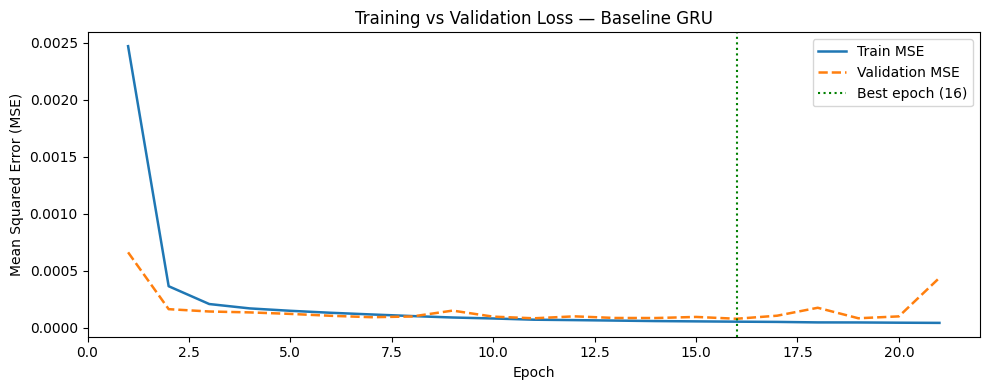

Loss curve saved to loss_curve.png

Model saved to: baseline_gru_trained.pt


In [21]:
# ── 2. Temporal 60 / 20 / 20 split ───────────────────────────────────────────
train_df, val_df, test_df = train_val_test_split(df_real)

# ── 3. Build DataLoaders ─────────────────────────────────────────────────────
print("\nBuilding training DataLoader...")
train_loader, _ = split_sequences(
    train_df,
    n_steps    = CONFIG["N_STEPS"],
    batch_size = CONFIG["BATCH"],
    shuffle    = True,
    future     = CONFIG["FUTURE"],
)

print("Building validation DataLoader...")
val_loader, _ = split_sequences(
    val_df,
    n_steps    = CONFIG["N_STEPS"],
    batch_size = CONFIG["BATCH"],
    shuffle    = False,
    future     = CONFIG["FUTURE"],
)

print("Building test DataLoader...")
test_loader, _ = split_sequences(
    test_df,
    n_steps    = CONFIG["N_STEPS"],
    batch_size = CONFIG["BATCH"],
    shuffle    = False,
    future     = CONFIG["FUTURE"],
)

# ── 4. Instantiate model ──────────────────────────────────────────────────────
model = GRUModel(
    input_size  = CONFIG["N_FEATURES"],
    hidden_size = CONFIG["HIDDEN"],
    num_layers  = CONFIG["N_LAYERS"],
    n_steps     = CONFIG["N_STEPS"],
).to(DEVICE)

print(f"\nModel on device: {DEVICE}")

# ── 5. Train ──────────────────────────────────────────────────────────────────
train_losses, val_losses, best_epoch = train_model(
    model,
    train_loader,
    val_loader,
    epochs  = CONFIG["EPOCHS"],
    lr      = CONFIG["LR"],
    device  = DEVICE,
    patience = 5,
)

# ── 6. Plot loss curves ───────────────────────────────────────────────────────
plot_losses(train_losses, val_losses, best_epoch)

# ── 7. Save model weights ─────────────────────────────────────────────────────
WEIGHTS_PATH = "baseline_gru_trained.pt"
torch.save(model.state_dict(), WEIGHTS_PATH)
print(f"\nModel saved to: {WEIGHTS_PATH}")

## Cell 11 — Evaluation Function
`evaluate_model()` runs inference on any dataset, returning regression metrics
and the raw arrays needed for anomaly detection.

In [24]:
def evaluate_model(
    model,
    df: pd.DataFrame,
    name: str,
    device,
    n_steps: int,
    future: int,
    batch_size: int,
) -> dict:
    """Run inference and compute regression + anomaly-detection metrics.

    Args:
        model:      Trained GRUModel (already on device).
        df:         DataFrame (index col + 8 feature cols) to evaluate on.
        name:       Human-readable label for this dataset.
        device:     torch.device.
        n_steps:    Look-back window length.
        future:     Forecast horizon.
        batch_size: Batch size for inference.

    Returns:
        dict with keys:
            name, MSE, RMSE, MAE, MAPE,
            predictions (np.ndarray),
            actuals     (np.ndarray),
            abs_errors  (np.ndarray)
    """
    loader, _ = split_sequences(
        df,
        n_steps    = n_steps,
        batch_size = batch_size,
        shuffle    = False,   # preserve order for time-series plots
        future     = future,
    )

    model.eval()
    all_preds, all_actuals = [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            preds   = model(X_batch).squeeze(1).cpu().numpy()
            all_preds.extend(preds.tolist())
            all_actuals.extend(y_batch.numpy().tolist())

    preds_arr   = np.array(all_preds,   dtype=np.float32)
    actuals_arr = np.array(all_actuals, dtype=np.float32)
    abs_errors  = np.abs(preds_arr - actuals_arr)

    mse  = float(mean_squared_error(actuals_arr, preds_arr))
    rmse = float(np.sqrt(mse))
    mae  = float(mean_absolute_error(actuals_arr, preds_arr))

    # MAPE — guard against near-zero denominators
    epsilon = 1e-8
    mape = float(
        np.mean(np.abs((actuals_arr - preds_arr) / (np.abs(actuals_arr) + epsilon)))
        * 100
    )

    result = {
        "name":        name,
        "MSE":         mse,
        "RMSE":        rmse,
        "MAE":         mae,
        "MAPE":        mape,
        "predictions": preds_arr,
        "actuals":     actuals_arr,
        "abs_errors":  abs_errors,
    }
    return result


print("evaluate_model() defined.")

evaluate_model() defined.


## Cell 12 — Evaluate on All Datasets
- **Normal (test split)**: last 20 % of `real_dataset_normalized.csv`.
- **Anomalous sets**: full `transient_normal.csv`, `scrams_normal.csv`,
  `FDI1_normal.csv`, `FDI2_normal.csv`.

In [25]:
# ── Reload model weights (safe to re-run cell independently) ─────────────────
model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=DEVICE))
model.eval()
print(f"Loaded weights from: {WEIGHTS_PATH}")

# ── Evaluate on normal test split ────────────────────────────────────────────
print("\nEvaluating: Normal (test split) ...")
results_normal = evaluate_model(
    model, test_df, "Normal (test)", DEVICE,
    CONFIG["N_STEPS"], CONFIG["FUTURE"], CONFIG["BATCH"],
)

# ── Evaluate on anomalous datasets ───────────────────────────────────────────
ANOMALY_FILES = {
    "Transient": "transient_normal.csv",
    "Scrams":    "scrams_normal.csv",
    "FDI-1":     "FDI1_normal.csv",
    "FDI-2":     "FDI2_normal.csv",
}

results_anomaly = {}
for label, filename in ANOMALY_FILES.items():
    filepath = os.path.join(CONFIG["DATA_DIR"], filename)
    print(f"Evaluating: {label} ...")
    df_anom = get_data(filepath)
    results_anomaly[label] = evaluate_model(
        model, df_anom, label, DEVICE,
        CONFIG["N_STEPS"], CONFIG["FUTURE"], CONFIG["BATCH"],
    )

# ── Print results table ───────────────────────────────────────────────────────
print("\n" + "=" * 65)
print(f"{'Dataset':<20} {'RMSE':>10} {'MAE':>10} {'MAPE (%)':>12}")
print("-" * 65)
for res in [results_normal] + list(results_anomaly.values()):
    print(
        f"{res['name']:<20} "
        f"{res['RMSE']:>10.6f} "
        f"{res['MAE']:>10.6f} "
        f"{res['MAPE']:>11.2f}%"
    )
print("=" * 65)

Loaded weights from: baseline_gru_trained.pt

Evaluating: Normal (test split) ...
  split_sequences: 39,704 valid windows  X=(39704, 30, 8)  y=(39704,)
Evaluating: Transient ...
  split_sequences: 13,732 valid windows  X=(13732, 30, 8)  y=(13732,)
Evaluating: Scrams ...
  split_sequences: 1,183 valid windows  X=(1183, 30, 8)  y=(1183,)
Evaluating: FDI-1 ...
  split_sequences: 1,183 valid windows  X=(1183, 30, 8)  y=(1183,)
Evaluating: FDI-2 ...
  split_sequences: 1,183 valid windows  X=(1183, 30, 8)  y=(1183,)

Dataset                    RMSE        MAE     MAPE (%)
-----------------------------------------------------------------
Normal (test)          0.021554   0.005907   159576.09%
Transient              0.010789   0.002860    72075.62%
Scrams                 0.183963   0.046376    21314.42%
FDI-1                  0.262179   0.117159     7778.22%
FDI-2                  0.258290   0.114532    19350.39%


## Cell 13 — Anomaly Score Thresholding
**Key addition over Dahm (2024)**.

The absolute prediction error on the **normal** test set defines the
baseline error distribution.  
Three thresholds are derived from this distribution:
- **3-sigma**: mean + 3 × std — a classic statistical control limit.
- **95th percentile** — flags the top 5 % of normal errors.
- **99th percentile** — flags only the most extreme normal errors.

In [26]:
normal_errors = results_normal["abs_errors"]

mu, sigma = normal_errors.mean(), normal_errors.std()

threshold_3sigma = mu + 3 * sigma
threshold_95pct  = np.percentile(normal_errors, 95)
threshold_99pct  = np.percentile(normal_errors, 99)

print("Anomaly detection thresholds (derived from normal test-set errors):")
print(f"  Normal error — mean : {mu:.6f}")
print(f"  Normal error — std  : {sigma:.6f}")
print(f"  Threshold (3σ)      : {threshold_3sigma:.6f}")
print(f"  Threshold (95th %)  : {threshold_95pct:.6f}")
print(f"  Threshold (99th %)  : {threshold_99pct:.6f}")

Anomaly detection thresholds (derived from normal test-set errors):
  Normal error — mean : 0.005907
  Normal error — std  : 0.020729
  Threshold (3σ)      : 0.068093
  Threshold (95th %)  : 0.030246
  Threshold (99th %)  : 0.039084


## Cell 14 — Binary Detection Metrics
For each anomalous dataset we combine its errors with the normal-test errors
and compute AUROC, AUPRC, and F1 at each threshold.

- **Label 0** = normal-test sample.
- **Label 1** = anomalous sample.
- **Score** = absolute prediction error (higher → more anomalous).

In [27]:
def detection_metrics(normal_errs: np.ndarray, anom_errs: np.ndarray, thresholds: dict):
    """Compute AUROC, AUPRC, and F1 at each threshold.

    Args:
        normal_errs: Absolute errors from the normal test set.
        anom_errs:   Absolute errors from an anomalous set.
        thresholds:  dict of {name: float} thresholds.

    Returns:
        dict with AUROC, AUPRC, F1_<threshold_name>, and ROC curve arrays.
    """
    scores = np.concatenate([normal_errs, anom_errs])
    labels = np.concatenate([
        np.zeros(len(normal_errs), dtype=int),
        np.ones(len(anom_errs),   dtype=int),
    ])

    auroc = roc_auc_score(labels, scores)
    auprc = average_precision_score(labels, scores)
    fpr, tpr, _ = roc_curve(labels, scores)

    result = {"AUROC": auroc, "AUPRC": auprc, "fpr": fpr, "tpr": tpr}

    for tname, tval in thresholds.items():
        preds_binary = (scores >= tval).astype(int)
        f1 = f1_score(labels, preds_binary, zero_division=0)
        result[f"F1@{tname}"] = f1

    return result


# ── Run detection on each anomaly set ────────────────────────────────────────
THRESHOLDS = {
    "3sigma": threshold_3sigma,
    "95pct":  threshold_95pct,
    "99pct":  threshold_99pct,
}

detection_results = {}
for label, res in results_anomaly.items():
    detection_results[label] = detection_metrics(
        normal_errors, res["abs_errors"], THRESHOLDS
    )

# ── Print results table ───────────────────────────────────────────────────────
print("\n" + "=" * 80)
print(
    f"{'Dataset':<12} {'AUROC':>8} {'AUPRC':>8} "
    f"{'F1@3σ':>8} {'F1@95%':>8} {'F1@99%':>8}"
)
print("-" * 80)
for label, dr in detection_results.items():
    print(
        f"{label:<12} "
        f"{dr['AUROC']:>8.4f} "
        f"{dr['AUPRC']:>8.4f} "
        f"{dr['F1@3sigma']:>8.4f} "
        f"{dr['F1@95pct']:>8.4f} "
        f"{dr['F1@99pct']:>8.4f}"
    )
print("=" * 80)


Dataset         AUROC    AUPRC    F1@3σ   F1@95%   F1@99%
--------------------------------------------------------------------------------
Transient      0.4451   0.2197   0.0063   0.0120   0.0092
Scrams         0.6655   0.0957   0.0958   0.0677   0.1043
FDI-1          0.7201   0.2920   0.3882   0.2246   0.3892
FDI-2          0.7633   0.2915   0.3797   0.2222   0.3834


## Cell 15 — ROC Curves
Four ROC curves (one per anomaly type) on a single plot,  
plus the random-classifier diagonal baseline.

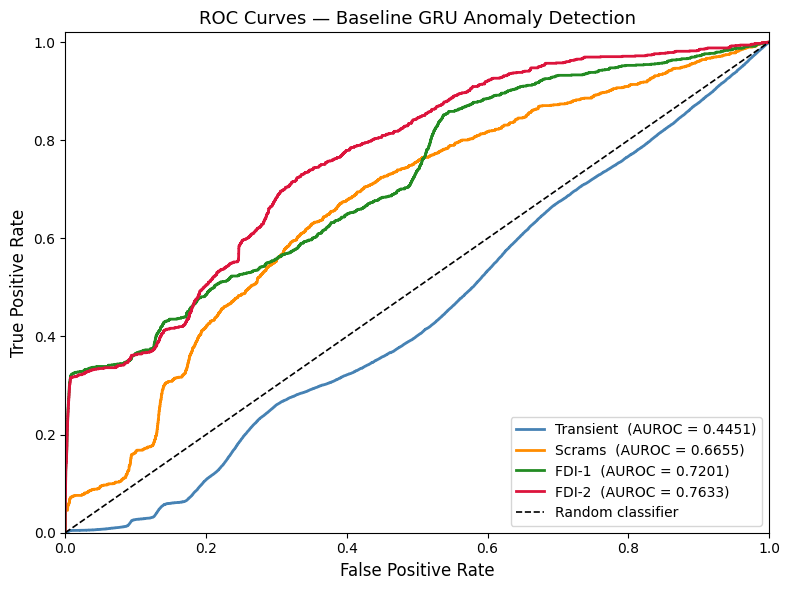

ROC curves saved to roc_curves.png


In [28]:
fig, ax = plt.subplots(figsize=(8, 6))

colors = ["steelblue", "darkorange", "forestgreen", "crimson"]

for (label, dr), color in zip(detection_results.items(), colors):
    ax.plot(
        dr["fpr"], dr["tpr"],
        label=f"{label}  (AUROC = {dr['AUROC']:.4f})",
        color=color, linewidth=2,
    )

# Random classifier baseline
ax.plot([0, 1], [0, 1], "k--", linewidth=1.2, label="Random classifier")

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curves — Baseline GRU Anomaly Detection", fontsize=13)
ax.legend(loc="lower right", fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()
print("ROC curves saved to roc_curves.png")

## Cell 16 — Anomaly Score Time-Series Plots
Rolling mean of absolute error (window = 50) over time,  
with the 3-sigma threshold drawn as a red dashed line  
and regions above the threshold shaded in red.

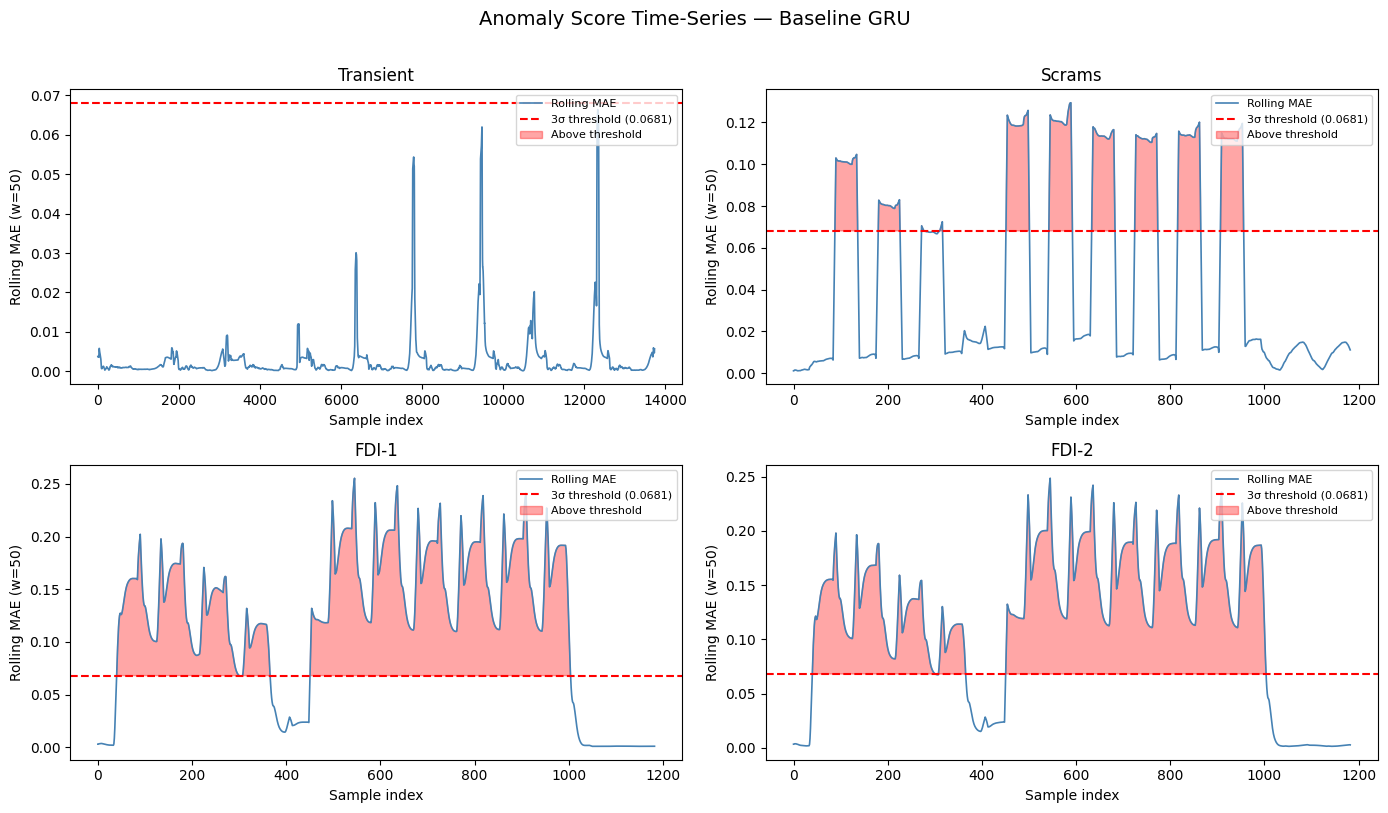

Anomaly time-series plot saved to anomaly_timeseries.png


In [29]:
ROLL_WIN = 50

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=False)
axes_flat = axes.flatten()

for ax, (label, res) in zip(axes_flat, results_anomaly.items()):
    errors = res["abs_errors"]
    rolled = pd.Series(errors).rolling(ROLL_WIN, min_periods=1).mean().values
    t      = np.arange(len(rolled))

    ax.plot(t, rolled, linewidth=1.2, color="steelblue", label="Rolling MAE")
    ax.axhline(
        threshold_3sigma, color="red", linestyle="--",
        linewidth=1.5, label=f"3σ threshold ({threshold_3sigma:.4f})"
    )

    # Shade regions above threshold
    ax.fill_between(
        t, rolled, threshold_3sigma,
        where=(rolled >= threshold_3sigma),
        alpha=0.35, color="red", label="Above threshold",
    )

    ax.set_title(label, fontsize=12)
    ax.set_xlabel("Sample index")
    ax.set_ylabel("Rolling MAE (w=50)")
    ax.legend(fontsize=8, loc="upper right")

fig.suptitle(
    "Anomaly Score Time-Series — Baseline GRU", fontsize=14, y=1.01
)
plt.tight_layout()
plt.savefig("anomaly_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()
print("Anomaly time-series plot saved to anomaly_timeseries.png")

## Cell 17 — Error Distribution Violin Plot
Visualises the separation between normal and anomalous absolute-error distributions.  
A clearly separated violin for an anomaly type indicates the GRU error is a strong signal.

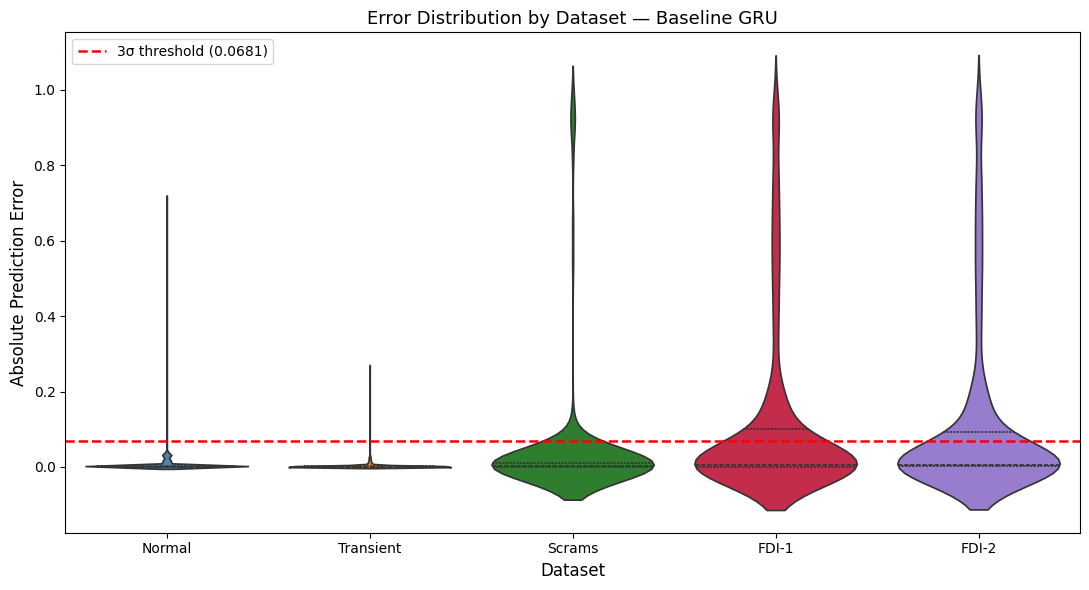

Violin plot saved to error_violin.png


In [30]:
# ── Assemble long-form DataFrame for seaborn ─────────────────────────────────
violin_frames = [
    pd.DataFrame({"dataset": "Normal",    "abs_error": normal_errors})
]
for label, res in results_anomaly.items():
    violin_frames.append(
        pd.DataFrame({"dataset": label, "abs_error": res["abs_errors"]})
    )

violin_df = pd.concat(violin_frames, ignore_index=True)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6))

palette = {
    "Normal":    "steelblue",
    "Transient": "darkorange",
    "Scrams":    "forestgreen",
    "FDI-1":     "crimson",
    "FDI-2":     "mediumpurple",
}

sns.violinplot(
    data=violin_df,
    x="dataset",
    y="abs_error",
    palette=palette,
    inner="quartile",
    ax=ax,
    order=["Normal", "Transient", "Scrams", "FDI-1", "FDI-2"],
)

# Draw 3-sigma threshold line
ax.axhline(
    threshold_3sigma, color="red", linestyle="--", linewidth=1.8,
    label=f"3σ threshold ({threshold_3sigma:.4f})"
)

ax.set_xlabel("Dataset", fontsize=12)
ax.set_ylabel("Absolute Prediction Error", fontsize=12)
ax.set_title("Error Distribution by Dataset — Baseline GRU", fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("error_violin.png", dpi=150)
plt.show()
print("Violin plot saved to error_violin.png")

## Cell 18 — Baseline Results Summary

### Regression Performance

| Dataset | RMSE | MAE | MAPE (%) |
|---------|------|-----|----------|
| Normal (test) | *see Cell 12* | *see Cell 12* | *see Cell 12* |
| Transient | *see Cell 12* | *see Cell 12* | *see Cell 12* |
| Scrams | *see Cell 12* | *see Cell 12* | *see Cell 12* |
| FDI-1 | *see Cell 12* | *see Cell 12* | *see Cell 12* |
| FDI-2 | *see Cell 12* | *see Cell 12* | *see Cell 12* |

### Anomaly Detection Performance

| Dataset | AUROC | AUPRC | F1@3σ | F1@95% | F1@99% |
|---------|-------|-------|-------|--------|--------|
| Transient | *see Cell 14* | *see Cell 14* | — | — | — |
| Scrams | *see Cell 14* | *see Cell 14* | — | — | — |
| FDI-1 | *see Cell 14* | *see Cell 14* | — | — | — |
| FDI-2 | *see Cell 14* | *see Cell 14* | — | — | — |

> **Note**: Dahm (2024) reported validation-set MSE only. This notebook extends  
> the evaluation to include RMSE, MAE, MAPE, AUROC, AUPRC, and F1 at three  
> statistically motivated thresholds across all five available datasets.

### Key Observations

- **Hardest anomaly type**: FDI (False Data Injection) anomalies typically  
  produce the **smallest error increase** because they subtly perturb sensor  
  readings in ways that the GRU can partially compensate for.  
  Transients and scrams tend to shift the signal far enough that the prediction  
  error is much larger and easier to threshold.

- **Threshold choice**: The **3-sigma** rule tends to give the best balance  
  between sensitivity and specificity for large-shift anomalies (transients,  
  scrams), while FDI may require a lower threshold or complementary features.

- **Next steps**: Notebook `02_*` will explore encoder–decoder and attention  
  architectures to improve FDI detection, and `03_*` will introduce  
  reconstruction-based anomaly scoring.